### Loading packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import math
from pathlib import Path

### Loading the data

In [2]:
Path.cwd()

WindowsPath('c:/Users/PC_DS_ECON_5/Desktop/data-analytics-python-example/notebooks')

In [3]:
PROJECT_DIR = 'c:/Users/PC_DS_ECON_5/Desktop/data-analytics-python-example'
DATA_DIR = PROJECT_DIR + '/data'

In [4]:
df = pd.read_parquet(DATA_DIR + '/nlsy97_emp_hed.parquet')

In [7]:
df.shape

(2556161, 10)

In [5]:
df2 = df.copy()

### Subsetting: years 2019-2020, sample 'Cross-sectional'

In [6]:
df2 = (
    df2
        # select observations such that the year is between 2019 and 2020
        # here I use isin() with a list of values
        # logical and in pandas is & 
        .loc[df['year'].isin([2019, 2020]) & 
        # sample == 'Cross-sectional' 
        # // in the context of the survey: representative for the particular generation
            df['sample'].eq('Cross-sectional') ,:]
        # because of removing observations -> so that index is the actual row index
        # optional / not absolutely necessary
        .reset_index(drop=True)
        .copy()
)

In [8]:
df2.shape

(129054, 10)

Objective:

 - how share of employed, unemployed, non-participant etc evolved around March 2020
 - monthly data
 - unit of observation: person X month
 - keep only individuals who have non-missing labor market status during the entire observation period (in all months): balanced panel

identify the individuals that are to kept
find a criterion

count number of non-missing observations (for the variable `emp_category`) per individual over the observation period 2019-2020

to identify non-missing values, we have `notna()`
to count non-missing values, we need to take a sum: `sum()`

In [ ]:
# the number of non-missing values for emp_category generally (unconditionally) 
# / not by individual
df2['emp_category'].notna().sum()

np.int64(129054)

objective: do the same by individual

grouping observations together: involves `groupby()`



In [16]:
# remark: transform can be used without grouping

# defining the function to be applied by group (after the grouping)
def count_nb_nonmissing(group):
    return group.notna().sum()

# in R (dplyr/tidyverse) the equivalent would be mutate()

df2['nb_nomissing_obs_by_individual'] = (
    df2
        # grouping observations by person_id
        # selecting the column emp_category
        .groupby(by=['person_id'])['emp_category']
        # by default: transform creates a single column
        # of the same length as the columns in the original data frame
        # appropriate for creating a new variable / column
        .transform(count_nb_nonmissing)
        .copy()
)


In [ ]:
df2['nb_nomissing_obs_by_individual']

0         24
1         24
2         24
3         24
4         24
          ..
129049    24
129050    24
129051    24
129052    24
129053    24
Name: nb_nomissing_obs_by_individual, Length: 129054, dtype: int64

In [ ]:
# keeping observations for individuals
# such that the number of observations per individual over the observation period is 24
df2 = (
    df2
        .loc[df2['nb_nomissing_obs_by_individual'].eq(24),:]
        .reset_index(drop=True)
        .copy()
)

In [21]:
# removing the variable nb_nomissing_obs_by_individual
df2 = df2.drop(columns=['nb_nomissing_obs_by_individual'])

Counting number of individuals in the remaining balanced panel

a possibility: using `drop_duplicates()` and `shape`

In [26]:

df2['person_id'].drop_duplicates().shape

(5131,)

Counting relative frequencies of employment status by month

First way: `df.value_counts()`

Second way: `pd.crosstab()`



In [29]:
df3 = (
    df2
        # grouping observations by month
        .groupby(by='year_month')['emp_category']
        # relative frequencies (normalize=True)
        .value_counts(normalize=True)
        # the index is meaningful, drop=False
        .reset_index()
        .copy()
)

In [32]:
# index=  rows of the cross-tabulation
# columns= columns of the cross-tabulation
# cross-tabulation of year_month (month) and emp_category (employment status)
# by default: contingency table, count table for each category

df3 = pd.crosstab(
    index=df2['year_month'],
    columns=df2['emp_category'],
    # relative frequencies by row
    # values by row add up to 1
    normalize='index'    
).reset_index()

In [34]:
df3.columns

Index(['year_month', 'employed', 'intermittently employed', 'military',
       'non-participant', 'unemployed'],
      dtype='string', name='emp_category')

In [36]:
# removing the name of the column-index
df3.columns.name = None
df3

,year_month,employed,intermittently employed,military,non-participant,unemployed
0,2019-01,0.796531,0.008380,0.012863,0.146755,0.035471
1,2019-02,0.798480,0.006626,0.012863,0.146365,0.035666
2,2019-03,0.798090,0.010329,0.012863,0.143637,0.035081
3,2019-04,0.802962,0.007406,0.012863,0.142857,0.033912
4,2019-05,0.801403,0.008965,0.012863,0.142467,0.034301
5,2019-06,0.796531,0.011304,0.012863,0.146170,0.033132
6,2019-07,0.797116,0.009160,0.012863,0.148899,0.031963
7,2019-08,0.798090,0.018515,0.012863,0.140518,0.030014
8,2019-09,0.803157,0.017346,0.012668,0.140129,0.026700
9,2019-10,0.807055,0.014032,0.012473,0.139934,0.026506


Plotting the cross-tabulation


Matplotlib:

plt.subplots()

empty figure with single axes
(matplotlib terminology)




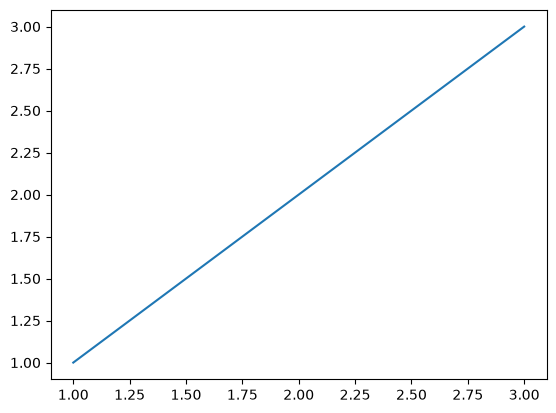

In [ ]:
# tuple of two objects that are related
# figure, I name it here: fig (convention)
# axes, I name it here: ax (convention)
# most of the time, it is the axes object 
# whose properties/attributes are to be set/adjust/specified
# on which most functions/methods are called with

# creates an empty plot (figure + single axes)
fig, ax = plt.subplots()



First objective: plot the share of employed by month
vertical (y-) axis: share of employed (`employed`)
horizontal (x-) axis: month of observation (`year_month`)

The variable `year_month` has Period datatype. This does not work with matplotlib.
datetime datatype

In [ ]:
df3['year_month'].dtype

period[M]

Convert the variable year_month to a datetime variable

with `dt.to_timestamp()`


In [44]:
# .dt.to_timestamp()
# freq is the desired frequency: daily frequency
# first day of the month: how='start'
df3['year_month_start'] = (
    # first day of the month
    df3['year_month'].dt.to_timestamp(freq='D', how='start')
)
print(df3['year_month_start'].dtype)

datetime64[us]


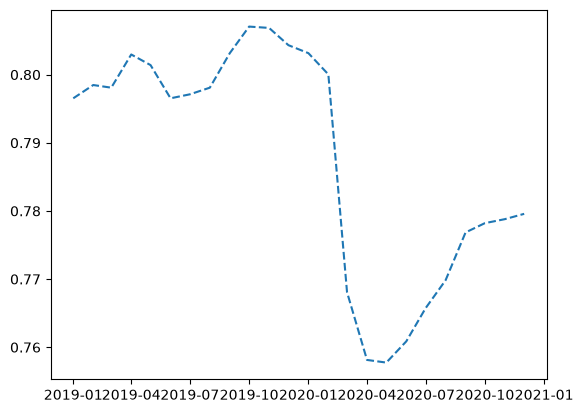

In [46]:
fig, ax = plt.subplots()
# plot() creates a line-plot
ax.plot(df3['year_month_start'], df3['employed'], linestyle='--')

<BarContainer object of 24 artists>

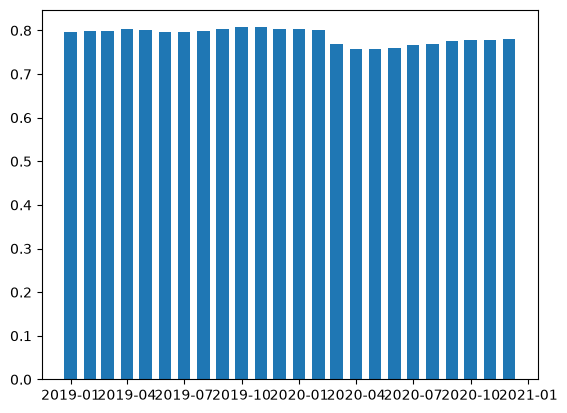

In [ ]:
fig, ax = plt.subplots()
# plot() creates a line-plot
ax.bar(
    # horizontal axis
    # time dimension / month (first day of the month)
    x=df3['year_month_start'], 
    # height of the bars
    # share of employed
    height=df3['employed'],
    # here the units are days because the horizontal axis is in days
    # (first day of the month)
    width=20
)
